# Exploring the listings

> Needs: pandas essentials (loading, selecting, grouping); the table that [`build_dataset.py`](build_dataset.py) builds.

Before a first model, a look at the table, to decide which listings and which columns that model can use. Each section ends with the decision it supports, and [A first model](00b_a_first_model.ipynb) applies them.

## The table

In [ ]:
from pathlib import Path

import pandas as pd

DATA_DIR = Path("data")

listings = pd.read_parquet(DATA_DIR / "idealista18_listings.parquet")
listings.shape

(189923, 44)

Its 44 columns, with the values of the first three listings:

In [ ]:
listings.head(3).T

,0,1,2
city,madrid,madrid,madrid
asset_id,A15019136831406238029,A6677225905472065344,A13341979748618524775
period,201803,201803,201803
price_eur,126000.0,235000.0,373000.0
unit_price_eur_m2,2680.851064,4351.851852,4973.333333
built_area_m2,47,54,75
bedrooms,1,1,2
bathrooms,1,1,1
has_terrace,0,0,0
has_lift,1,0,0


One row per listing and quarter, with:

- the **target**, `price_eur`: the asking price, in euros;
- the home itself: its size (`built_area_m2`, `bedrooms`, `bathrooms`), yes/no amenities (`has_lift`, `has_terrace`…), its construction year and floor, its condition, furnishing and outlook;
- data from the Spanish cadastre about its building (`cadastre_*`);
- where it is: its coordinates, its distances to the city centre, to the nearest metro station and to the city's main street, and its neighbourhood;
- its city, its quarter (`period`) and the listing's identifier (`asset_id`).

What the listings are and what they aren't (asking prices, with noise added on purpose to every price and location) is in the README, under *Data and licence*.

## The target

In [ ]:
listings["price_eur"].describe().round(0)

count     189923.0
mean      361226.0
std       351674.0
min        20000.0
25%       160000.0
50%       261000.0
75%       428000.0
max      8133000.0
Name: price_eur, dtype: float64

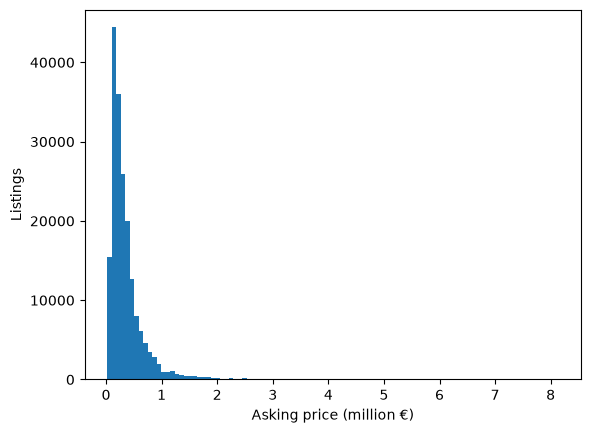

In [ ]:
import matplotlib.pyplot as plt

plt.hist(listings["price_eur"] / 1e6, bins=100)
plt.xlabel("Asking price (million €)")
plt.ylabel("Listings")
plt.show()

Half of the asking prices are between €160,000 and €428,000, but the mean, €361,000, is well above the median, €261,000: a long tail of expensive homes, 4% of them above €1 million and the most expensive at €8.1 million. A model fitted by minimising squared errors gives those few homes a large weight. **Decision:** the first model predicts the price as it is, and its errors are worth reading by price range, not only on average.

## A column computed from the target

`unit_price_eur_m2`, the price per square metre, sounds like a property of the home. Compared with the price divided by the area:

In [ ]:
float((listings["unit_price_eur_m2"] - listings["price_eur"] / listings["built_area_m2"]).abs().max())

6.366462912410498e-12

The difference is rounding: the column *is* the price divided by the area, computed from the target. A model given it would multiply it by the area and get the price back, which nobody can do for a home whose price is unknown. **Decision:** it is never an input of a model.

## Missing values

The share of missing values of each column that has any:

In [ ]:
missing_share = listings.isna().mean()
missing_share[missing_share > 0].sort_values(ascending=False).round(4)

dist_blasco_km        0.8230
dist_diagonal_km      0.6763
dist_castellana_km    0.5008
construction_year     0.4847
outlook               0.1030
floor                 0.0518
neighbourhood_id      0.0002
neighbourhood         0.0002
cadastre_quality      0.0000
dtype: float64

The three main-street distances are empty outside their own city, since each city measures it to a different street. The construction year is missing in about half of the listings, the outlook in one in ten and the floor in one in twenty; a handful of listings have no neighbourhood or no cadastre quality. **Decision:** the first model uses only complete columns, so that no row has to be filled in or dropped for a gap.

## What goes with the price

Within one city, so that the price levels of the three cities don't mix: the correlation of each numerical column with the price in Madrid, the strongest first. It goes from −1 to 1, and measures how closely two columns rise and fall together along a straight line:

In [ ]:
madrid = listings[listings["city"] == "madrid"]
numerical_columns = madrid.select_dtypes("number").drop(columns="price_eur").astype("float64")
correlation = numerical_columns.corrwith(madrid["price_eur"].astype("float64"))
correlation.sort_values(key=abs, ascending=False).head(12).round(2)

built_area_m2                0.86
bathrooms                    0.72
unit_price_eur_m2            0.59
bedrooms                     0.46
cadastre_quality            -0.46
has_doorman                  0.35
has_lift                     0.32
dist_castellana_km          -0.25
latitude                     0.25
has_box_room                 0.22
has_parking_space            0.22
parking_included_in_price    0.22
dtype: float64

The size of the home leads: the area, then the bathrooms, then the bedrooms. `unit_price_eur_m2` is high only because it contains the price. Other columns go with the price too, such as the cadastre's quality grade, a doorman or a lift. The distance to the centre is not among these twelve:

In [ ]:
correlation[["dist_city_centre_km"]].round(2)

dist_city_centre_km   -0.2
dtype: float64

Weak on this measure, but a correlation only sees straight lines (next section). **Decision:** the size of the home, as `built_area_m2`, `bedrooms` and `bathrooms`, enters the first model; a first model keeps to a few columns whose meaning is plain.

## Where the home is

The coordinates of each city, from the smallest to the largest:

In [ ]:
listings.groupby("city")[["latitude", "longitude"]].agg(["min", "max"]).round(2)

latitude        longitude      
               min    max       min   max
city                                     
barcelona    41.33  41.47      2.09  2.22
madrid       36.76  40.52     -3.83 -2.75
valencia     39.44  39.50     -0.42 -0.32

Each city occupies its own small box of coordinates (Madrid's reaches 36.76° and −2.75° because of one listing far from the city, below). A latitude means something different in each city, and the distances to the main street are three different columns, one per city. The distance to the city centre is the one location column that means the same in every city. How the median price per square metre changes with it in Madrid:

In [ ]:
price_per_m2 = listings["price_eur"] / listings["built_area_m2"]
distance_band = pd.cut(madrid["dist_city_centre_km"], [0, 1, 2, 3, 4, 6, 8, 10, 15, 500])

pd.DataFrame({
    "listings": madrid.groupby(distance_band, observed=True).size(),
    "median price per m² (€)": price_per_m2[madrid.index].groupby(distance_band, observed=True).median(),
}).round(0)

,listings,median price per m² (€)
dist_city_centre_km,,
"(0, 1]",8266,4843.0
"(1, 2]",9589,4740.0
"(2, 3]",14553,4820.0
"(3, 4]",13327,3600.0
"(4, 6]",23697,2515.0
"(6, 8]",14449,2480.0
"(8, 10]",7599,2510.0
"(10, 15]",3334,3133.0
"(15, 500]",1,1317.0


Within 3 km of the centre a square metre is asked about €4,800; from 4 to 10 km, about €2,500, half as much; beyond 10 km it rises again, to about €3,100. (The last band is the single listing far from the city.) The relation is strong, and not a straight line, which is why the correlation missed it; and the distance alone can't tell an expensive outer district from a cheap one. **Decision:** `dist_city_centre_km` is the first model's one location column; the coordinates and the neighbourhood are left out of it.

## Three cities, three markets

In [ ]:
pd.DataFrame({
    "listings": listings.groupby("city").size(),
    "median price per m² (€)": price_per_m2.groupby(listings["city"]).median(),
}).round(0)

,listings,median price per m² (€)
city,,
barcelona,61486,3991.0
madrid,94815,3480.0
valencia,33622,1531.0


A square metre in Valencia costs less than half of one in Madrid or Barcelona. A model that sees the listings of the three cities, but no column that says which city each one is in, can only price each home at some mix of three markets. **Decision:** the first model learns one market, Madrid, the largest, with half of the listings.

## Values that can't be right

The range of the first model's columns in Madrid:

In [ ]:
FEATURES = ["built_area_m2", "bedrooms", "bathrooms", "dist_city_centre_km"]
TARGET = "price_eur"

madrid[FEATURES + [TARGET]].astype("float64").describe().T.round(1)

,count,mean,std,min,25%,50%,75%,max
built_area_m2,94815.0,101.4,67.1,21.0,62.0,83.0,117.0,985.0
bedrooms,94815.0,2.6,1.2,0.0,2.0,3.0,3.0,93.0
bathrooms,94815.0,1.6,0.8,0.0,1.0,1.0,2.0,20.0
dist_city_centre_km,94815.0,4.5,3.0,0.0,2.4,4.1,6.2,415.8
price_eur,94815.0,396110.1,417074.4,21000.0,160000.0,262000.0,467000.0,8133000.0


Two maxima stand out. The listings farthest from the centre:

In [ ]:
madrid.nlargest(3, "dist_city_centre_km")[["dist_city_centre_km", "latitude", "longitude"]]

,dist_city_centre_km,latitude,longitude
84000,415.752584,36.756391,-2.753303
66109,14.158814,40.444980,-3.540911
66090,14.157997,40.444620,-3.540814


One listing is 415.8 km from the centre of Madrid, and the next one 14.2 km: its coordinates are in the province of Almería, far to the south. Its location is an error, and a distance thirty times larger than any other would weigh heavily on a straight line fitted through the data. **Decision:** it is dropped.

And the homes with the most bedrooms:

In [ ]:
madrid.nlargest(3, "bedrooms")[FEATURES + [TARGET]]

,built_area_m2,bedrooms,bathrooms,dist_city_centre_km,price_eur
17638,119,93,2,7.020016,450000.0
84059,90,33,2,3.609483,109000.0
544,847,20,16,0.593355,2020000.0


93 bedrooms in 119 m², or 33 in 90 m², are errors; 20 bedrooms in 847 m² may well be a real house. **Decision:** errors like these are few among almost 95,000 listings, and the first model leaves them as they are.

## Decisions

What [A first model](00b_a_first_model.ipynb) takes from this exploration:

| What the exploration showed | Decision for the first model |
| --- | --- |
| A long tail of expensive homes | The price is predicted as it is, and the errors are read by price range |
| `unit_price_eur_m2` is the price divided by the area | Never an input |
| The construction year, the outlook and the floor have gaps | Only complete columns |
| The size of the home goes with the price most closely | `built_area_m2`, `bedrooms` and `bathrooms` |
| The distance to the centre means the same in every city, and the price per m² changes with it, though not along a straight line | `dist_city_centre_km`, the one location column |
| Each city is its own market | Madrid only |
| One Madrid listing is 415 km from the centre | Dropped |
| A few impossible bedroom counts | Left as they are |